# 高斯 RBF-KAN 建筑供暖和制冷负荷预测
本 Notebook 独立训练和评估高斯 RBF-KAN，沿用项目的随机行划分和建筑形状划分。运行结果保存到 results/kan/。以相同的数据划分与 MLP 比较。

**运行方法**：从项目目录打开 Notebook，选择 **Restart Kernel and Run All**（重启内核并运行全部单元格）。运行需要 Python、NumPy、pandas、openpyxl 和 Pillow，可按需通过 requirements.txt 安装。Notebook 直接读取同目录下的 UCI 原始工作簿，无需联网。训练耗时会随硬件而变化。

**数据来源**：Tsanas 和 Xifara（2012），[UCI Energy Efficiency](https://doi.org/10.24432/C51307)，采用 CC BY 4.0 许可。**KAN 架构参考**：[Liu 等人（2024）](https://arxiv.org/abs/2404.19756)。**高斯基函数参考**：[Li（2024）](https://arxiv.org/abs/2405.06721)。**优化器参考**：[Kingma 和 Ba](https://arxiv.org/abs/1412.6980)。


In [1]:
import os
for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import hashlib
import importlib.metadata
import json
import platform
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont



DATA = Path("ENB2012_data.xlsx")
MODEL = "kan"
OUT = Path("results") / MODEL
OUT.mkdir(parents=True, exist_ok=True)
FEATURES = ["X" + str(i) for i in range(1, 9)]
TARGETS = ["Y1", "Y2"]
NAMES = ["Heating", "Cooling"]
NUMERIC = ["X1", "X2", "X3", "X4", "X5", "X7"]
CATEGORIES = {"X6": (2, 3, 4, 5), "X8": (0, 1, 2, 3, 4, 5)}
SPLIT_SEED = 2026
TUNE_SEED = 17
FINAL_SEEDS = (101, 202, 303)
MAX_EPOCHS = 250
PATIENCE = 35
BATCH_SIZE = 64
ENV = dict(
    python=platform.python_version(), platform=platform.platform(),
    cpu=os.environ.get("PROCESSOR_IDENTIFIER") or platform.processor(),
    logical_cpus=os.cpu_count(), numpy=np.__version__, pandas=pd.__version__,
    openpyxl=importlib.metadata.version("openpyxl"),
    blas_threads_requested=1, dtype="float32", split_seed=SPLIT_SEED,
    tuning_seed=TUNE_SEED, evaluation_seeds=FINAL_SEEDS,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, batch=BATCH_SIZE,
)
ENV["data_sha256"] = hashlib.sha256(DATA.read_bytes()).hexdigest()


## 第一步　检查数据与展开输入

从 Excel 读取 768 条记录，检查缺失值、重复输入、非有限数值和类别编号。保留 X1–X5 和 X7 六个数值特征，把 X6 的四种朝向和 X8 的六种玻璃分布展开成指示列。数据因此从 **768 行 × 8 个输入特征**变成 **768 行 × 16 列输入**。这一步会显示前四行，方便和原表对照。供暖和制冷负荷 Y1、Y2 单独保存为预测目标。

此时前六列先保留原数值。固定类别的独热编码可以在划分前完成，数值标准化则要等各自的训练集确定后再做。


In [2]:
df = pd.read_excel(DATA, usecols=FEATURES + TARGETS)
assert df.shape == (768, 10)
assert df.notna().all().all() and not df[FEATURES].duplicated().any()
assert np.isfinite(df.to_numpy()).all()
for key, values in CATEGORIES.items():
    assert set(df[key]) == set(values)

# 先按固定类别展开 X6 和 X8，再与六个数值特征拼接。
input_columns = NUMERIC + [
    f"{field}_{level}"
    for field, levels in CATEGORIES.items()
    for level in levels
]
category_indicators = [
    (df[field].to_numpy()[:, None] == levels).astype(np.float32)
    for field, levels in CATEGORIES.items()
]
encoded_inputs = pd.DataFrame(
    np.column_stack([df[NUMERIC].to_numpy(np.float32), *category_indicators]),
    columns=input_columns,
)
assert encoded_inputs.shape == (768, 16)
print(f"编码后：{encoded_inputs.shape[0]} 行 × {encoded_inputs.shape[1]} 列")
print(encoded_inputs.head(4).to_string(index=False))

def preprocess(split):
    train = df.iloc[split["train"]]
    def scale(cols):
        mean = train[cols].mean().to_numpy(np.float32)
        sd = train[cols].std(ddof=0).to_numpy(np.float32)
        sd = np.where(sd > 0, sd, 1)
        return ((df[cols].to_numpy(np.float32) - mean) / sd, mean, sd)
    design = encoded_inputs.to_numpy(copy=True)
    design[:, :len(NUMERIC)], _, _ = scale(NUMERIC)
    target, y_mean, y_std = scale(TARGETS)
    return design, target, y_mean, y_std

SPLITS = {}
DESIGN = {}
manifest = pd.DataFrame({"row_id": np.arange(len(df))})

def register_split(name, split):
    indices = np.sort(np.concatenate(list(split.values())))
    assert np.array_equal(indices, np.arange(len(df)))
    for part, idx in split.items():
        manifest.loc[idx, name] = part
    design = preprocess(split)
    assert design[0].shape == (768, 16)
    SPLITS[name] = split
    DESIGN[name] = design



编码后：768 行 × 16 列
  X1    X2    X3     X4  X5  X7  X6_2  X6_3  X6_4  X6_5  X8_0  X8_1  X8_2  X8_3  X8_4  X8_5
0.98 514.5 294.0 110.25 7.0 0.0   1.0   0.0   0.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0
0.98 514.5 294.0 110.25 7.0 0.0   0.0   1.0   0.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0
0.98 514.5 294.0 110.25 7.0 0.0   0.0   0.0   1.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0
0.98 514.5 294.0 110.25 7.0 0.0   0.0   0.0   0.0   1.0   1.0   0.0   0.0   0.0   0.0   0.0


## 第二步　随机按行划分

用固定种子打乱 768 行记录，取前 538 行训练、中间 115 行验证、最后 115 行测试。同一建筑形状的记录可以分到不同集合，因此这套实验考察模型能否预测熟悉形状的新朝向或玻璃配置。用这套划分的训练集计算数值特征和两个负荷目标的均值与标准差，并把同一组统计量应用到验证集和测试集。


In [3]:
row = np.random.default_rng(SPLIT_SEED).permutation(len(df))
register_split("row", dict(train=row[:538], val=row[538:653], test=row[653:]))


## 第三步　按建筑形状划分

把 X1–X5 五个输入值完全相同的记录归为一组。整份数据共有 12 组，每组 64 条记录。用固定随机种子打乱组的顺序，再按整组划分：

- **训练集**：8 组，共 512 条记录。
- **验证集**：2 组，共 128 条记录。
- **测试集**：2 组，共 128 条记录。

同一组的 64 条记录会一起进入同一个集合。保留原来的两组验证形状，把原测试集按固定顺序的第一组移到训练集。

用这套划分自己的训练集计算标准化统计量。两套划分都完成后，本单元会保存划分明细，并导出 KAN_Preprocessed_16_Inputs.xlsx。两个工作表按原始 Excel 的行顺序显示实际送进模型的 16 列输入。随后训练时用验证集挑选配置和决定早停，用测试集计算最终误差。


In [4]:
geometry_keys = sorted(set(df[FEATURES[:5]].itertuples(index=False, name=None)))
geometry_map = {g: i + 1 for i, g in enumerate(geometry_keys)}
geometry_id = np.asarray([geometry_map[g] for g in
                          df[FEATURES[:5]].itertuples(index=False, name=None)])
assert len(geometry_keys) == 12
shapes = np.random.default_rng(SPLIT_SEED).permutation(np.arange(1, 13))
shape_split = dict(
    train=np.flatnonzero(np.isin(geometry_id, np.r_[shapes[:7], shapes[9]])),
    val=np.flatnonzero(np.isin(geometry_id, shapes[7:9])),
    test=np.flatnonzero(np.isin(geometry_id, shapes[10:])),
)
manifest["geometry_id"] = geometry_id
manifest = manifest[["row_id", "geometry_id", "row"]]
register_split("shape", shape_split)
assert all(manifest.groupby("geometry_id")["shape"].nunique() == 1)
manifest.to_csv(OUT / "split_manifest.csv", index=False)
for part, group in manifest.groupby("shape", sort=False):
    ids = sorted(group["geometry_id"].unique().tolist())
    print(f"{part}: {len(group)} rows, geometry IDs {ids}")

# 两套划分都完成后，导出实际进入模型的 16 列输入。
input_tables = {
    "随机按行": pd.DataFrame(DESIGN["row"][0], columns=input_columns),
    "按建筑形状": pd.DataFrame(DESIGN["shape"][0], columns=input_columns),
}
input_workbook = DATA.with_name("KAN_Preprocessed_16_Inputs.xlsx")
with pd.ExcelWriter(input_workbook, engine="openpyxl") as writer:
    for sheet_name, table in input_tables.items():
        table.to_excel(writer, sheet_name=sheet_name, index=False, freeze_panes=(1, 0))
print(f"已导出 {input_workbook.name}，每个工作表包含 768 行、16 列模型输入。")


train: 512 rows, geometry IDs [1, 2, 3, 7, 8, 9, 10, 12]
test: 128 rows, geometry IDs [5, 11]
val: 128 rows, geometry IDs [4, 6]
已导出 KAN_Preprocessed_16_Inputs.xlsx，每个工作表包含 768 行、16 列模型输入。


## 高斯 RBF-KAN 模型

网络只有一个隐藏层。两层里的每条连接都先把自己的输入变成一条可学习的曲线，再由接收节点把所有连接的贡献与偏置相加。对输入 $x$，一条连接的曲线为

$$F(x)=\sum_{k=1}^{11} c_k\exp\!\left[-\left(\frac{x-g_k}{s}\right)^2\right].$$

固定中心 $g_k$ 从 −2.5 到 2.5，间距为 0.5。高斯函数的尺度 $s$ 也固定为 0.5。输入等于中心时，基函数值为 1，该项贡献恰好是 $c_k$。相距 0.5 时，基函数值约为 0.368，相距 1.0 时约为 0.018。随着距离增大，高斯项平滑地趋近于零。训练会更新 11 个高斯系数 $c_k$ 和各节点的偏置。

隐藏层宽度候选为 4、6、8，每种宽度尝试两个学习率。按验证集上的平均均方误差选择配置，并保留每次训练中验证误差最低的模型参数。


In [5]:
CENTERS = np.linspace(-2.5, 2.5, 11, dtype=np.float32)
GAUSSIAN_SCALE = np.float32(0.5)
ENV["kan_basis"] = "gaussian_rbf_only"
ENV["kan_centers"] = CENTERS.tolist()
ENV["kan_gaussian_scale"] = float(GAUSSIAN_SCALE)

def gaussian_basis(x):
    u = (x[:, :, None] - CENTERS) / GAUSSIAN_SCALE
    basis = np.exp(-u**2)
    derivative = (-2 * u / GAUSSIAN_SCALE) * basis
    return basis, derivative

class Layer:
    def __init__(self, inputs, outputs, rng):
        factors = len(CENTERS)
        self.weights = rng.normal(0, 1 / np.sqrt(inputs * factors),
                                  (inputs * factors, outputs)).astype(np.float32)
        self.bias = np.zeros(outputs, np.float32)

    def forward(self, x):
        basis, derivative = gaussian_basis(x)
        self.x = basis.reshape(len(x), -1)
        self.derivative = derivative
        return self.x @ self.weights + self.bias

    def backward(self, output_gradient):
        dw = self.x.T @ output_gradient
        db = output_gradient.sum(axis=0)
        incoming = output_gradient @ self.weights.T
        incoming = (incoming.reshape(self.derivative.shape) * self.derivative).sum(axis=2)
        return incoming, (dw, db)

class Network:
    def __init__(self, width, seed, inputs=16):
        rng = np.random.default_rng(seed)
        self.first = Layer(inputs, width, rng)
        self.second = Layer(width, 2, rng)
        self.parameters = [self.first.weights, self.first.bias,
                           self.second.weights, self.second.bias]

    def predict(self, x):
        hidden = self.first.forward(x)
        return self.second.forward(hidden)

    def backward(self, grad):
        delta, second = self.second.backward(grad)
        _, first = self.first.backward(delta)
        return (*first, *second)

def gradient_check():
    rng = np.random.default_rng(4)
    x = rng.normal(size=(4, 16)).astype(np.float32)
    y = rng.normal(size=(4, 2)).astype(np.float32)
    net = Network(3, 4)
    residual = net.predict(x) - y
    grads = net.backward(2 * residual / residual.size)
    for param, grad in zip(net.parameters, grads, strict=True):
        idx = np.unravel_index(np.argmax(np.abs(grad)), grad.shape)
        value = param[idx].copy()
        eps = 0.001
        param[idx] = value + eps
        right = ((net.predict(x) - y)**2).mean()
        param[idx] = value - eps
        left = ((net.predict(x) - y)**2).mean()
        param[idx] = value
        np.testing.assert_allclose(grad[idx], (right-left)/(2*eps), rtol=0.02, atol=0.0002)

gradient_check()
# 中心处高斯基函数为 1，斜率为 0。离中心越远，基函数值越小。
probe = np.array([[0.0], [0.5], [1.0], [-0.5]], dtype=np.float64)
values, derivatives = gaussian_basis(probe)
middle = len(CENTERS) // 2
np.testing.assert_allclose(values[:, 0, middle], np.exp(-np.array([0, 1, 4, 1])))
eps = 1e-5
left, _ = gaussian_basis(probe - eps)
right, _ = gaussian_basis(probe + eps)
np.testing.assert_allclose(derivatives, (right - left) / (2 * eps), atol=1e-8)
print("高斯基函数与网络的梯度检查通过。")

高斯基函数与网络的梯度检查通过。


## 验证与最终训练
损失函数是标准化负荷的均方误差。本模型使用 Adam，沿用对比实验的动量参数、训练轮数上限、早停耐心值和打乱后的批次。批次顺序由随机种子决定。计时涵盖训练、验证、复制最佳模型参数和最终恢复这些参数。预处理、创建模型、调参、绘图和测试评分均在计时范围之外。

对于每种数据划分，先用种子 17 做六次验证试验，再用预先设定的三个种子分别训练最佳配置。配置选定后才在测试集上评分。每次最终训练都根据自己的验证结果选出最佳轮次。


In [6]:
@dataclass(frozen=True)
class Config:
    model: str
    width: int
    lr: float

CANDIDATES = [Config(MODEL, width, lr) for width in (4, 6, 8)
              for lr in (0.003, 0.01)]

def fit(x, y, train, val, cfg, seed):
    net = Network(cfg.width, seed)
    rng = np.random.default_rng(seed + 10000)
    params = net.parameters
    first = [np.zeros_like(p) for p in params]
    second = [np.zeros_like(p) for p in params]
    best, best_epoch, step = float("inf"), 0, 0
    history = []
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        shuffled = rng.permutation(train)
        for offset in range(0, len(shuffled), BATCH_SIZE):
            idx = shuffled[offset:offset+BATCH_SIZE]
            err = net.predict(x[idx]) - y[idx]
            grads = net.backward(2 * err / err.size)
            step += 1
            alpha = cfg.lr * np.sqrt(1 - 0.999**step) / (1 - 0.9**step)
            epsilon = 1e-8 * np.sqrt(1 - 0.999**step)
            for p, g, m, v in zip(params, grads, first, second, strict=True):
                m *= 0.9
                m += 0.1 * g
                v *= 0.999
                v += 0.001 * g**2
                p -= alpha * m / (np.sqrt(v) + epsilon)
        score = float(np.mean((net.predict(x[val]) - y[val])**2))
        if not np.isfinite(score):
            raise FloatingPointError(f"Nonfinite validation loss for {cfg}")
        history.append(score)
        if score < best:
            best, best_epoch = score, epoch
            snapshot = [p.copy() for p in params]
        if epoch - best_epoch >= PATIENCE:
            break
    for p, saved in zip(params, snapshot, strict=True):
        p[...] = saved
    seconds = time.perf_counter() - start
    return net, dict(val_mse=best, best_epoch=best_epoch, epochs=len(history),
                     seconds=seconds, params=sum(p.size for p in params)), history

tuning, runs, predictions, history_rows = [], [], [], []
for protocol, split in SPLITS.items():
    x, y, center, scale = DESIGN[protocol]
    selected = None
    best_val = float('inf')
    for cfg in CANDIDATES:
        _, stat, _ = fit(x, y, split["train"], split["val"], cfg, TUNE_SEED)
        tuning.append(dict(protocol=protocol, **vars(cfg), **stat))
        if stat['val_mse'] < best_val:
            selected, best_val = cfg, stat['val_mse']

    idx = split["test"]
    actual = df.iloc[idx][TARGETS].to_numpy()
    for seed in FINAL_SEEDS:
        net, stat, history = fit(x, y, split["train"], split["val"], selected, seed)
        if protocol == "row" and seed == FINAL_SEEDS[0]:
            # 保留最终选中的模型，供后面查看 x1 到第一个隐藏节点的连接。
            f1_demo_model = net
        pred = net.predict(x[idx]) * scale + center
        signature = dict(protocol=protocol, model=MODEL, seed=seed)
        record = dict(**signature, width=selected.width, lr=selected.lr, **stat)
        for j, target in enumerate(NAMES):
            residual = pred[:, j] - actual[:, j]
            record[target + "_MAE"] = np.mean(np.abs(residual))
            record[target + "_RMSE"] = np.sqrt(np.mean(residual**2))
        runs.append(record)
        history_rows.extend(dict(**signature, epoch=i, val_mse=mse)
                            for i, mse in enumerate(history, 1))
        predictions.extend(dict(**signature, row_id=int(row_id),
                                geometry_id=int(geometry_id[row_id]),
                                heating_actual=actual[k, 0], cooling_actual=actual[k, 1],
                                heating_pred=pred[k, 0], cooling_pred=pred[k, 1])
                           for k, row_id in enumerate(idx))
        print(protocol, seed, "finished", flush=True)

metrics = pd.DataFrame(runs).sort_values(["protocol", "model", "seed"])
pred = pd.DataFrame(predictions)
curves = pd.DataFrame(history_rows)
metrics.to_csv(OUT / "runs.csv", index=False)
pred.to_csv(OUT / "predictions.csv", index=False)
curves.to_csv(OUT / "learning_curves.csv", index=False)
trial_table = pd.DataFrame(tuning)
trial_table.to_csv(OUT / "tuning.csv", index=False)
summary = metrics.groupby(["protocol", "model"])[
    ["Heating_MAE", "Heating_RMSE", "Cooling_MAE", "Cooling_RMSE",
     "seconds", "params", "epochs", "best_epoch"]].agg(["mean", "std"])
summary.columns = ["_".join(col) for col in summary.columns]
summary.to_csv(OUT / "summary.csv")
(OUT / "environment.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")
assert len(metrics) == 6 and len(trial_table) == 12
assert all(len(g) == len(SPLITS[p]["test"]) for (p, _, _), g in
           pred.groupby(["protocol", "model", "seed"]))
print(summary.round(4).to_string())

row 101 finished
row 202 finished
row 303 finished
shape 101 finished
shape 202 finished
shape 303 finished
                Heating_MAE_mean  Heating_MAE_std  Heating_RMSE_mean  Heating_RMSE_std  Cooling_MAE_mean  Cooling_MAE_std  Cooling_RMSE_mean  Cooling_RMSE_std  seconds_mean  seconds_std  params_mean  params_std  epochs_mean  epochs_std  best_epoch_mean  best_epoch_std
protocol model                                                                                                                                                                                                                                                              
row      kan              0.4184           0.0098             0.5569            0.0071            0.7007           0.1447             1.0314            0.2595        0.1823       0.1031       1196.0         0.0     146.3333     83.8113         111.3333         83.8113
shape    kan              4.7344           0.5100             5.1003            0.672

## 图表检查与解读
预测散点图使用预先指定的第一个最终训练种子（101）。汇总表中的指标是三个种子结果的平均值。对角线 y=x 表示预测值与仿真值完全一致。散点偏离对角线、误差整体偏向一侧，都可能反映模型对留出形状的敏感程度。

表中的标准差反映固定数据划分下，模型初始化和批次顺序变化带来的波动。它无法衡量更换数据划分后的不确定性，也不足以判断某个模型是否具有统计上的优势。


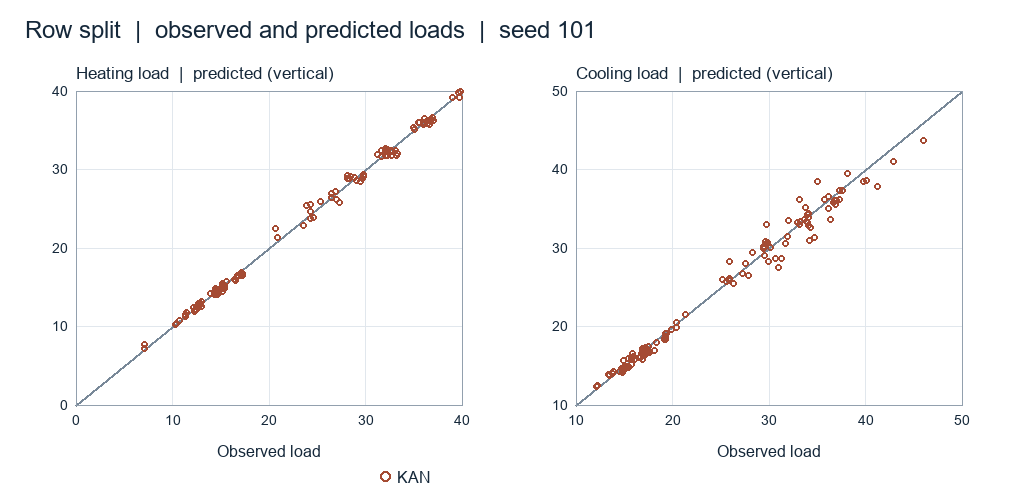

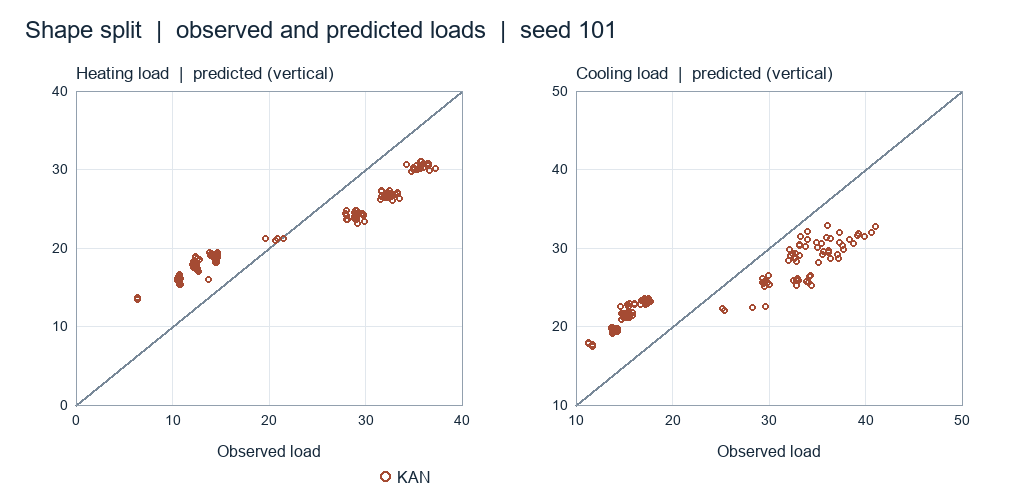

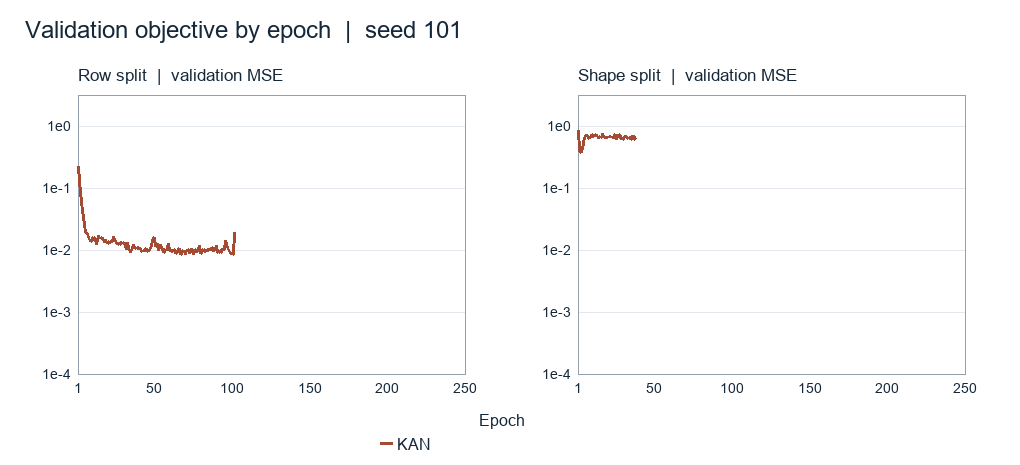

In [7]:
def show_png(path):
    renderer = globals().get("_notebook_image_renderer")
    if renderer:
        renderer(path)
    else:
        from IPython.display import Image as DisplayImage, display
        display(DisplayImage(filename=str(path)))

def font(size):
    try:
        return ImageFont.truetype("DejaVuSans.ttf", size)
    except OSError:
        try:
            return ImageFont.truetype("arial.ttf", size)
        except OSError:
            return ImageFont.load_default(size=size)

PALETTE = {MODEL: "#A54B33"}
INK = "#15283A"

def scatter_plot(protocol):
    image = Image.new("RGB", (1020, 500), "white")
    draw = ImageDraw.Draw(image)
    draw.text((25, 16), f"{protocol.title()} split  |  observed and predicted loads  |  seed 101",
              fill=INK, font=font(24))
    data = pred.query("protocol == @protocol and seed == 101")
    for j, target in enumerate(("heating", "cooling")):
        x0, y0, x1, y1 = 76+j*500, 91, 462+j*500, 405
        obs, estimates = f"{target}_actual", f"{target}_pred"
        lo = np.floor(data[[obs, estimates]].min().min()/10)*10
        hi = np.ceil(data[[obs, estimates]].max().max()/10)*10
        def xy(x, y):
            return (x0+(x-lo)/(hi-lo)*(x1-x0), y1-(y-lo)/(hi-lo)*(y1-y0))
        for tick in np.linspace(lo, hi, 5):
            tx, ty = xy(tick, tick)
            draw.line((tx,y0,tx,y1), fill="#E1E7ED")
            draw.line((x0,ty,x1,ty), fill="#E1E7ED")
            draw.text((tx, y1+10), f"{tick:g}", font=font(14), fill=INK, anchor="mt")
            draw.text((x0-8, ty), f"{tick:g}", font=font(14), fill=INK, anchor="rm")
        draw.line((*xy(lo,lo), *xy(hi,hi)), fill="#788898", width=2)
        draw.rectangle((x0,y0,x1,y1), outline="#92A0AE", width=1)
        for model, group in data.groupby("model", sort=False):
            for a, b in zip(group[obs], group[estimates], strict=True):
                px, py = xy(a,b)
                draw.ellipse((px-3,py-3,px+3,py+3), outline=PALETTE[model], width=2)
        draw.text((x0, 63), target.title() + " load  |  predicted (vertical)",
                  font=font(17), fill=INK)
        draw.text(((x0+x1)/2, 445), "Observed load", font=font(16), fill=INK, anchor="mt")
    for j, (model, color) in enumerate(PALETTE.items()):
        x = 380+145*j
        draw.ellipse((x,471,x+10,481), outline=color, width=2)
        draw.text((x+17,468), model.upper(), font=font(16), fill=INK)
    path = OUT / f"{protocol}_predictions.png"
    image.save(path)
    show_png(path)

def validation_plot():
    image = Image.new("RGB", (1020, 465), "white")
    draw = ImageDraw.Draw(image)
    draw.text((25, 16), "Validation objective by epoch  |  seed 101", font=font(24), fill=INK)
    for j, protocol in enumerate(SPLITS):
        x0,y0,x1,y1 = 78+j*500, 95, 465+j*500, 374
        data = curves.query("protocol == @protocol and seed == 101")
        lo, hi = -4.0, 0.5
        def xy(epoch, loss):
            return x0+(epoch-1)/(MAX_EPOCHS-1)*(x1-x0), y1-(np.log10(loss)-lo)/(hi-lo)*(y1-y0)
        for exponent in range(-4,1):
            _,ty = xy(1, 10.0**exponent)
            draw.line((x0,ty,x1,ty), fill="#E1E7ED")
            draw.text((x0-7,ty), f"1e{exponent}", fill=INK, font=font(14), anchor="rm")
        draw.rectangle((x0,y0,x1,y1), outline="#92A0AE")
        draw.text((x0,65), protocol.title()+" split  |  validation MSE", font=font(17), fill=INK)
        for ep in (1, 50, 100, 150, 200, 250):
            tx,_=xy(ep,1)
            draw.text((tx,y1+9), str(ep), font=font(14), fill=INK, anchor="mt")
        for model, group in data.groupby("model"):
            draw.line([xy(e,m) for e,m in zip(group.epoch, group.val_mse, strict=True)],
                      width=3, fill=PALETTE[model])
    draw.text((502, 414), "Epoch", font=font(16), fill=INK, anchor="mt")
    for j, (model, color) in enumerate(PALETTE.items()):
        x = 380+145*j
        draw.line((x,443,x+12,443), fill=color, width=3)
        draw.text((x+17,435), model.upper(), font=font(16), fill=INK)
    path = OUT / "validation_curves.png"
    image.save(path)
    show_png(path)

for protocol in SPLITS:
    scatter_plot(protocol)
validation_plot()

## 实际算例　训练好的 F₁(x₁) 长什么样

取随机按行实验、种子 101、验证误差最低时的高斯 RBF-KAN。只看**标准化后的 X1（相对紧凑度）到第一个隐藏节点**的连接。固定原表第一条记录的其他 15 个模型输入，在横轴上逐点改变 x₁，先算出隐藏节点实际输出 h₁，再减去偏置和其他 15 条连接的贡献。剩下的就是这条连接的 F₁(x₁)。

这里把 x₁ 从 −3.5 扫到 3.5，是为了观察曲线在所有网格附近的形状。超出训练数据范围的点只用于理解公式。


In [8]:
row_inputs = DESIGN["row"][0]
scan_x1 = np.linspace(-3.5, 3.5, 281)
scan_inputs = np.repeat(row_inputs[:1].astype(np.float64), len(scan_x1), axis=0)
scan_inputs[:, 0] = scan_x1

hidden_layer = f1_demo_model.first
hidden_output = hidden_layer.forward(scan_inputs)[:, 0]
term_count = len(CENTERS)
edge_basis = hidden_layer.x[:, :term_count].copy()
trained_edge_weights = hidden_layer.weights[:term_count, 0].astype(np.float64)
other_connections = hidden_layer.x[:, term_count:] @ hidden_layer.weights[term_count:, 0]
fixed_contribution = other_connections + hidden_layer.bias[0]
np.testing.assert_allclose(fixed_contribution, fixed_contribution[0])
f1_target = hidden_output - fixed_contribution
np.testing.assert_allclose(f1_target, edge_basis @ trained_edge_weights, atol=1e-12)

print(f"固定的其他连接与偏置合计：{fixed_contribution[0]:.6f}")
print(pd.DataFrame({"x1": scan_x1, "h1": hidden_output, "F1(x1)": f1_target})
      .iloc[::40].round(6).to_string(index=False))


固定的其他连接与偏置合计：-0.498431
  x1        h1    F1(x1)
-3.5 -0.500636 -0.002204
-2.5 -0.582781 -0.084350
-1.5 -0.680946 -0.182515
-0.5 -0.718859 -0.220428
 0.5 -0.257582  0.240850
 1.5 -0.553480 -0.055049
 2.5 -0.956030 -0.457598
 3.5 -0.504760 -0.006328


### 把 F₁ 曲线当作学习目标

先把 11 个新系数都设为 0。每次用当前系数算 F₁ 的预测值，与上面提取的曲线比较，再按梯度下降更新。每个系数的梯度是 **2 × 所有采样点上「预测误差 × 该基函数值」的平均**。表里记录第 0、1、20、200、8000 次更新后的系数，并对照真实 KAN 权重。

这是为了看清一条连接而做的重建实验。原 KAN 训练时，用的是建筑的供暖和制冷标签，11 个系数跟其他权重一起通过反向传播更新。这里的重建把已学会的 F₁ 当作目标。


In [9]:
edge_weights = np.zeros(term_count)
checkpoints = (0, 1, 20, 200, 8000)
edge_history = {}
# 用损失曲率选一个稳定的固定学习率。
curvature = 2 * np.linalg.norm(edge_basis, ord=2)**2 / len(scan_x1)
edge_lr = 1 / curvature

for step in range(checkpoints[-1] + 1):
    error = edge_basis @ edge_weights - f1_target
    if step in checkpoints:
        edge_history[step] = (edge_weights.copy(), float(np.mean(error**2)))
    if step < checkpoints[-1]:
        gradient = 2 * (edge_basis.T @ error) / len(scan_x1)
        edge_weights -= edge_lr * gradient

term_labels = [f"Gaussian, center {float(center):g}" for center in CENTERS]
coefficient_table = pd.DataFrame({"项": term_labels, "原模型权重": trained_edge_weights})
for step in checkpoints:
    coefficient_table[f"更新 {step} 次"] = edge_history[step][0]
print(coefficient_table.round(6).to_string(index=False))
print()
for step, (_, mse) in edge_history.items():
    print(f"更新 {step:>4} 次  MSE = {mse:.3e}")


                    项     原模型权重  更新 0 次    更新 1 次   更新 20 次  更新 200 次  更新 8000 次
Gaussian, center -2.5 -0.121077     0.0 -0.032592 -0.102146 -0.121080  -0.121077
  Gaussian, center -2  0.107855     0.0 -0.035166  0.073914  0.107863   0.107855
Gaussian, center -1.5 -0.160007     0.0 -0.092934 -0.125845 -0.160026  -0.160007
  Gaussian, center -1 -0.155810     0.0 -0.136810 -0.176673 -0.155776  -0.155810
Gaussian, center -0.5 -0.144234     0.0 -0.107922 -0.142173 -0.144286  -0.144234
   Gaussian, center 0 -0.053870     0.0 -0.007124 -0.039903 -0.053801  -0.053870
 Gaussian, center 0.5  0.209820     0.0  0.099490  0.187051  0.209739   0.209820
   Gaussian, center 1  0.145138     0.0  0.091747  0.169210  0.145222   0.145138
 Gaussian, center 1.5  0.008364     0.0 -0.045686 -0.011618  0.008290   0.008364
   Gaussian, center 2 -0.310843     0.0 -0.202786 -0.297725 -0.310790  -0.310843
 Gaussian, center 2.5 -0.343417     0.0 -0.218042 -0.349110 -0.343441  -0.343417

更新    0 次  MSE = 4.849e-02


### 看曲线怎么接近目标

第一张图左边是固定其他输入时的 h₁，灰线标出其他连接与偏置的合计。右边把扣除该合计后得到的 F₁ 当作目标，对照从零开始的拟合过程。第二张图把这条连接拆成 **11 个加权高斯项**。在同一个横坐标把这些项相加，就得到 F₁(x₁)。各小图纵轴单独缩放，便于看清较小的贡献。


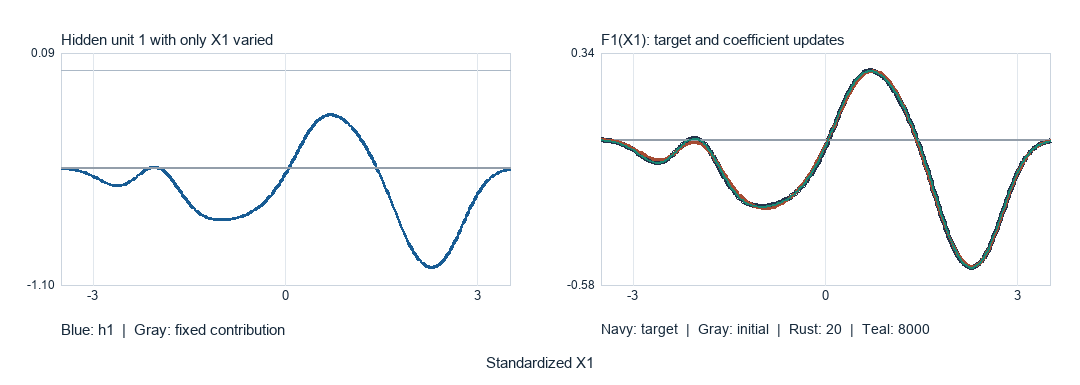

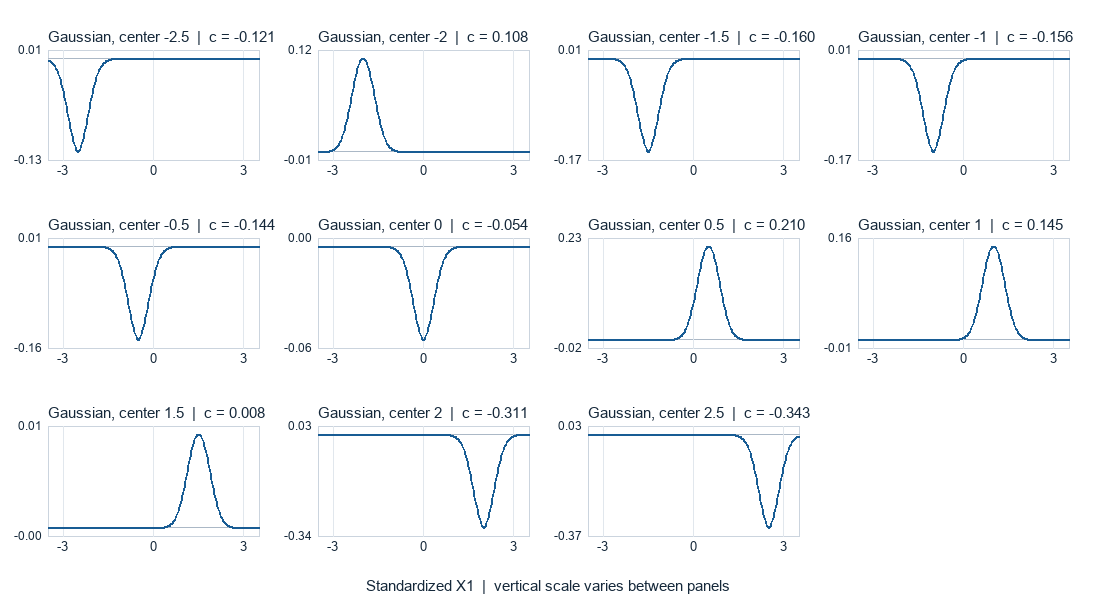

In [10]:
def draw_edge_panel(draw, box, lines, title):
    left, top, right, bottom = box
    lo = min(0, *(float(np.min(y)) for y, _, _ in lines))
    hi = max(0, *(float(np.max(y)) for y, _, _ in lines))
    span = max(hi - lo, 1e-10)
    lo, hi = lo - 0.09 * span, hi + 0.09 * span
    def x_px(x):
        return left + (x - scan_x1[0]) / (scan_x1[-1] - scan_x1[0]) * (right - left)
    def y_px(y):
        return bottom - (y - lo) / (hi - lo) * (bottom - top)
    draw.rectangle(box, outline="#CBD4DE")
    draw.line((left, y_px(0), right, y_px(0)), fill="#ABB8C6", width=1)
    for tick in (-3, 0, 3):
        xp = x_px(tick)
        draw.line((xp, top, xp, bottom), fill="#E1E7ED", width=1)
        draw.text((xp, bottom+5), str(tick), fill=INK, font=font(13), anchor="mt")
    draw.text((left-6, y_px(hi),), f"{hi:.2f}", fill=INK, font=font(12), anchor="rm")
    draw.text((left-6, y_px(lo),), f"{lo:.2f}", fill=INK, font=font(12), anchor="rm")
    for y, color, thickness in lines:
        draw.line([(x_px(x), y_px(v)) for x, v in zip(scan_x1, y, strict=True)],
                  fill=color, width=thickness)
    draw.text((left, top-22), title, fill=INK, font=font(15))

canvas = Image.new("RGB", (1080, 385), "white")
draw = ImageDraw.Draw(canvas)
learned = edge_basis @ edge_history[checkpoints[-1]][0]
draw_edge_panel(draw, (61, 53, 510, 285),
                [(hidden_output, "#185C94", 3), (fixed_contribution, "#939EAA", 2)],
                "Hidden unit 1 with only X1 varied")
draw_edge_panel(draw, (601, 53, 1050, 285),
                [(f1_target, "#24334A", 5), (edge_basis @ edge_history[0][0], "#939EAA", 2),
                 (edge_basis @ edge_history[20][0], "#A54B33", 3), (learned, "#178875", 2)],
                "F1(X1): target and coefficient updates")
draw.text((61, 321), "Blue: h1  |  Gray: fixed contribution", fill=INK, font=font(15))
draw.text((601, 321), "Navy: target  |  Gray: initial  |  Rust: 20  |  Teal: 8000", fill=INK, font=font(14))
draw.text((540, 357), "Standardized X1", fill=INK, font=font(15), anchor="mt")
path = OUT / "f1_reconstruction.png"
canvas.save(path)
show_png(path)

canvas = Image.new("RGB", (1100, 616), "white")
draw = ImageDraw.Draw(canvas)
for i, name in enumerate(term_labels):
    row, col = divmod(i, 4)
    x0, y0 = 48 + col*270, 50 + row*188
    component = trained_edge_weights[i] * edge_basis[:, i]
    draw_edge_panel(draw, (x0, y0, x0+211, y0+110), [(component, "#185C94", 2)],
                    f"{name}  |  c = {trained_edge_weights[i]:.3f}")
draw.text((548, 580), "Standardized X1  |  vertical scale varies between panels",
          fill=INK, font=font(15), anchor="mt")
path = OUT / "f1_weighted_components.png"
canvas.save(path)
show_png(path)
